# Equivalent ESS bids and Baldick's SOC-based design: numerical check

This notebook reproduces, step by step, every numerical result of the equivalence note on **Baldick's single-bus example** [1, §4.7]:

1. Solve the SOC-based design and read prices, schedule and multipliers.
2. Build the equivalent bids (E) and clear the current design with them (Props 1–2).
3. Check Corollary 3 (bids from the value of stored energy, max/min form).
4. Rebuild $\pi$ from prices only (Proposition 4).
5. Admissible range of $\pi$ from technical data, prices and one schedule (Lemma 4, Proposition 5), and the pre-limit rule.
6. Theorem 1 at every extreme point of the range.
7. Summary over the three cases (Table 3 and Figures 1–2 of the note).
8. Computational burden of both designs.

Run all cells from top to bottom (*Kernel → Restart & Run All*). Everything uses NumPy, SciPy (HiGHS) and Matplotlib; total run time is about one minute.

[1] R. Baldick, *A state-of-charge based formulation for storage participation in electricity markets: Technical reference*, arXiv:2606.14993, 2026.

In [2]:
import numpy as np
import pandas as pd
from IPython.display import Image, display
import verify_equivalence as V      # SOC and current-design LPs, multipliers in the note's sign convention
import verify_price_based as P      # self-schedule, Prop. 5 polyhedron, dual optimal face
import numerical_check as NC        # all checks + figures for the three cases
import computational_burden as CB   # size and timing benchmark
pd.set_option("display.precision", 3)
hours = [f"t={t}" for t in range(1, 7)]

## 1. SOC-based design, base case

One bus, $T=6$ intervals of $\Delta T=4$ h, renewable at 0 \$/MWh, thermal 100 MW at 50 \$/MWh. ESS: $\alpha=0.9$, $\beta=1$, $\gamma=1$, $\epsilon=\zeta=1$, $\bar s=800$ MWh, $s_0=0$, $\bar p=\bar g=1000$ MW, terminal value $w=40$ \$/MWh.

Sign convention (same as the note): the Lagrangian is $f+\text{multiplier}\times(\text{lhs}-\text{rhs})$, and multipliers of MW rows are divided by $\Delta T$, so every multiplier is in \$/MWh. `V.duals` does this conversion from SciPy's raw marginals.

In [3]:
case = V.baldick_case(smax=800, w=40)
T, dT, S = case["T"], case["dT"], case["ess"][0]
lp, res, _ = V.build(case, "SOC")
y, ub, lb = V.duals(case, lp, res)
I, x = lp.idx, res.x

lam = np.array([y["lam", 0, t] for t in range(T)])
pi  = np.array([y["pi", 0, t] for t in range(T)])
nU  = np.array([y["nuU", 0, t] for t in range(T)])   # upper SOC limit (A9): nu-bar
nL  = np.array([y["nuL", 0, t] for t in range(T)])   # lower SOC limit (A10): nu-underbar
p   = np.array([x[I["p", 0, t]] for t in range(T)])
g   = np.array([x[I["g", 0, t]] for t in range(T)])
s   = np.array([x[I["s", 0, t]] for t in range(T)])

pd.DataFrame({"price λ*": lam, "charge p*": p, "discharge g*": g, "SOC s*": s,
              "π*": pi, "ν̄* (full)": nU, "ν̲* (empty)": nL, "rent r = ν̲−ν̄": nL - nU},
             index=hours).T.round(2) + 0.0

,t=1,t=2,t=3,t=4,t=5,t=6
price λ*,43.1,50.00,0.00,0.00,50.0,50.0
charge p*,100.0,0.00,200.00,22.22,0.0,0.0
discharge g*,0.0,90.00,0.00,0.00,175.0,25.0
SOC s*,360.0,0.00,720.00,800.00,100.0,0.0
π*,49.0,1.11,1.11,49.00,49.0,40.0
ν̄* (full),0.0,0.00,0.00,47.89,0.0,0.0
ν̲* (empty),0.0,47.89,0.00,0.00,0.0,9.0
rent r = ν̲−ν̄,0.0,47.89,0.00,-47.89,0.0,9.0


**Reading.** The battery empties at $t=2$ and $t=6$ and fills at $t=4$, which is where the SOC rents are non-zero. The value of stored energy $\pi^\star$ jumps exactly there.

## 2. Equivalent bids (E) and the current design (Propositions 1–2)

$$u_t=\alpha(\pi_t-\bar\nu_t)-\epsilon,\qquad c_t=\zeta+\beta(\pi_t+\underline\nu_t),\qquad \hat p=\bar p,\ \hat g=\bar g.$$

We clear the current design with these bids and compare prices and objective values. $K$ is the constant of Proposition 2.

In [4]:
u = S["a"] * (pi - nU) - S["eps"]
c = S["zet"] + S["b"] * (pi + nL)
lpC, resC, capC = P.capture_build(case, "CD", {"u": [u], "c": [c]})
lamC = np.array([-resC.eqlin.marginals[k] / dT for k, tag in enumerate(lpC.tagE) if tag[0] == "lam"])

# current-design objective evaluated at Baldick's dispatch
xc = np.zeros(lpC.nv)
for key, j in lpC.idx.items():
    xc[j] = x[I[key]]
f_cd_at_soc, f_cd_opt = capC["c"] @ xc, resC.fun

# Proposition 2: f_SOC = f_CD + K
sbb = S["g"] ** T * S["s0"]
pi0 = S["g"] * (pi[0] - nU[0] + nL[0])
K = -pi0 * S["s0"] - S["smax"] * nU.sum() + S["smin"] * nL.sum() + S["w"] * sbb
f_soc = res.fun + S["w"] * sbb

display(pd.DataFrame({"bid u": u, "offer c": c, "λ* (SOC design)": lam, "λ (current design)": lamC},
                     index=hours).T.round(2))
print(f"max |λ_CD − λ*|            = {np.abs(lamC - lam).max():.1e}")
print(f"f_CD(Baldick dispatch)     = {f_cd_at_soc:.4f}   f_CD optimum = {f_cd_opt:.4f}   -> Baldick's dispatch is CD-optimal")
print(f"f_SOC = {f_soc:.4f}   f_CD + K = {f_cd_opt + K:.4f}   (Proposition 2)")

,t=1,t=2,t=3,t=4,t=5,t=6
bid u,43.1,0.0,0.00,0.0,43.1,35.0
offer c,50.0,50.0,2.11,50.0,50.0,50.0
λ* (SOC design),43.1,50.0,0.00,0.0,50.0,50.0
λ (current design),43.1,50.0,0.00,0.0,50.0,50.0


max |λ_CD − λ*|            = 2.9e-15
f_CD(Baldick dispatch)     = 57760.0000   f_CD optimum = 57760.0000   -> Baldick's dispatch is CD-optimal
f_SOC = 19448.8889   f_CD + K = 19448.8889   (Proposition 2)


Every $\lambda^\star_t$ sits on an edge of the band $[u_t,c_t]$ (Proposition 3). The CD solver may itself return another dispatch with the same cost and prices (ties at the band edges, Remark 1); what matters is that Baldick's dispatch attains the CD optimum.

## 3. Corollary 3: bids from the value of stored energy

$$c_t=\zeta+\beta\max\Big\{\pi_t,\tfrac{\pi_{t-1}}{\gamma}\Big\},\qquad u_t=\alpha\min\Big\{\pi_t,\tfrac{\pi_{t-1}}{\gamma}\Big\}-\epsilon,$$

with the convention $\pi_0/\gamma:=\pi_1-\bar\nu_1+\underline\nu_1$.

In [5]:
pi_prev = np.r_[pi[0] - nU[0] + nL[0], pi[:-1] / S["g"]]      # value at the start of each interval
c_cor3 = S["zet"] + S["b"] * np.maximum(pi, pi_prev)
u_cor3 = S["a"] * np.minimum(pi, pi_prev) - S["eps"]
display(pd.DataFrame({"π_t (end)": pi, "π_{t-1}/γ (start)": pi_prev, "c from (E)": c, "c from Cor. 3": c_cor3,
                      "u from (E)": u, "u from Cor. 3": u_cor3}, index=hours).T.round(2))
print("max difference:", max(np.abs(c - c_cor3).max(), np.abs(u - u_cor3).max()))

,t=1,t=2,t=3,t=4,t=5,t=6
π_t (end),49.0,1.11,1.11,49.00,49.0,40.0
π_{t-1}/γ (start),49.0,49.00,1.11,1.11,49.0,49.0
c from (E),50.0,50.00,2.11,50.00,50.0,50.0
c from Cor. 3,50.0,50.00,2.11,50.00,50.0,50.0
u from (E),43.1,0.00,0.00,0.00,43.1,35.0
u from Cor. 3,43.1,0.00,0.00,0.00,43.1,35.0


max difference: 0.0


## 4. Proposition 4: $\pi$ from prices only

Segments are delimited by the binding intervals. In each segment we find a **marginal interval** (partial trade, no SOC limit binding) and read the value from its price: $v=(\lambda-\zeta)/\beta$ for a partial discharge, $v=(\lambda+\epsilon)/\alpha$ for a partial charge. The last segment takes the terminal value $w$.

In [6]:
pi_prices = NC.price_based_pi(S, lam, p, g, nU, nL, T)
pd.DataFrame({"π* (solver)": pi, "π from prices (Prop. 4)": pi_prices}, index=hours).T.round(3)

,t=1,t=2,t=3,t=4,t=5,t=6
π* (solver),49.0,1.111,1.111,49.0,49.0,40.0
π from prices (Prop. 4),49.0,1.111,1.111,49.0,49.0,40.0


## 5. Admissible range of $\pi$ from technical data and prices (Lemma 4, Proposition 5) and the pre-limit rule

The battery solves its own self-schedule at $\lambda^\star$ (only $\theta_e$ and prices). From **one** optimal schedule, Proposition 5 gives a polyhedron of admissible multipliers; we compute the range of each $\pi_t$ by LP and cross-check it against the dual optimal face.

The pre-limit rule keeps the carried-in value whenever it is admissible:
$\pi^R_t=\min\{\max\{\pi^R_{t-1}/\gamma,\ \pi^-_t\},\ \pi^+_t\}$.

In [7]:
rss, css = P.self_schedule(S, lam, T, dT)
print(f"Lemma 4: self-schedule optimum {rss.fun:.4f}, value of Baldick's schedule {css @ np.r_[p, g, s]:.4f}")
poly = P.prop5_polyhedron(S, lam, rss.x[:T], rss.x[T:2*T], rss.x[2*T:], T, dT)
rng, pts = P.pi_range(poly, T)
face = P.dual_face_range(S, lam, T, dT, rss.fun)

piR = np.zeros(T)
for t in range(T):
    lo, hi = rng[t]
    cand = piR[t - 1] / S["g"] if t > 0 else hi
    piR[t] = min(max(cand, lo), hi)

pd.DataFrame({"π⁻ (Prop. 5)": [a for a, b in rng], "π⁺ (Prop. 5)": [b for a, b in rng],
              "π⁻ (dual face)": [a for a, b in face], "π⁺ (dual face)": [b for a, b in face],
              "π* solver": pi, "π pre-limit": piR}, index=hours).T.round(3)

Lemma 4: self-schedule optimum -38311.1111, value of Baldick's schedule -38311.1111


,t=1,t=2,t=3,t=4,t=5,t=6
π⁻ (Prop. 5),49.0,1.111,1.111,1.111,49.0,40.0
π⁺ (Prop. 5),49.0,49.000,1.111,49.000,49.0,40.0
π⁻ (dual face),49.0,1.111,1.111,1.111,49.0,40.0
π⁺ (dual face),49.0,49.000,1.111,49.000,49.0,40.0
π* solver,49.0,1.111,1.111,49.000,49.0,40.0
π pre-limit,49.0,49.000,1.111,1.111,49.0,40.0


$\pi$ is unique except at $t=2$ (battery empty) and $t=4$ (battery full), where any value in $[1.11, 49]$ is admissible. The solver picks the lower end at $t=2$ and the upper end at $t=4$; the pre-limit rule picks the opposite ends.

## 6. Theorem 1: every extreme point gives equivalent bids

For each extreme point of the ranges we build the bids, clear the current design, and check its KKT conditions at Baldick's dispatch and prices.

In [8]:
rows = []
for k, xp in enumerate(pts):
    pe, nUe, nLe = xp[:T], xp[T:2*T], xp[2*T:]
    ue = S["a"] * (pe - nUe) - S["eps"]; ce = S["zet"] + S["b"] * (pe + nLe)
    lpE, resE, capE = P.capture_build(case, "CD", {"u": [ue], "c": [ce]})
    lamE = np.array([-resE.eqlin.marginals[i] / dT for i, tag in enumerate(lpE.tagE) if tag[0] == "lam"])
    xe = np.zeros(lpE.nv)
    for key, j in lpE.idx.items():
        xe[j] = x[I[key]]
    rows.append({"extreme point": f"{'min' if k % 2 == 0 else 'max'} π_{k // 2 + 1}",
                 "π": np.round(pe, 2), "max |λ_CD − λ*|": np.abs(lamE - lam).max(),
                 "f_CD(x*) − f_CD*": capE["c"] @ xe - resE.fun})
pd.DataFrame(rows)

,extreme point,π,max |λ_CD − λ*|,f_CD(x*) − f_CD*
0,min π_1,"[49.0, 49.0, 1.11, 1.11, 49.0, 40.0]",2.887e-15,0.000e+00
1,max π_1,"[49.0, 1.11, 1.11, 1.11, 49.0, 40.0]",2.887e-15,0.000e+00
2,min π_2,"[49.0, 1.11, 1.11, 1.11, 49.0, 40.0]",2.887e-15,0.000e+00
3,max π_2,"[49.0, 49.0, 1.11, 1.11, 49.0, 40.0]",2.887e-15,0.000e+00
4,min π_3,"[49.0, 1.11, 1.11, 1.11, 49.0, 40.0]",2.887e-15,0.000e+00
5,max π_3,"[49.0, 1.11, 1.11, 1.11, 49.0, 40.0]",2.887e-15,0.000e+00
6,min π_4,"[49.0, 1.11, 1.11, 1.11, 49.0, 40.0]",2.887e-15,0.000e+00
7,max π_4,"[49.0, 1.11, 1.11, 49.0, 49.0, 40.0]",2.887e-15,7.276e-12
8,min π_5,"[49.0, 1.11, 1.11, 1.11, 49.0, 40.0]",2.887e-15,0.000e+00
9,max π_5,"[49.0, 1.11, 1.11, 1.11, 49.0, 40.0]",2.887e-15,0.000e+00


## 7. All three cases of Baldick's §4.7 (Table 3 and Figures 1–2 of the note)

Base case ($\bar s=800$, $w=40$), higher terminal value ($w=55$), larger battery ($\bar s=1200$).

In [9]:
R = [NC.run_case(*cs) for cs in NC.CASES]
labels = {"kkt": "KKT residual (S1)–(S8)", "lam": "max |λ_CD − λ*| (Prop. 1)", "obj": "f_CD(x*) − f_CD* rel. (Prop. 1)",
          "p2": "f_SOC − (f_CD + K) rel. (Prop. 2)", "p4": "max |π_prices − π*| (Prop. 4)",
          "l4": "self-schedule gap (Lemma 4)", "p5": "Prop. 5 vs dual face", "t1": "CD KKT violation, extreme bids (Thm. 1)"}
table = pd.DataFrame({name: [r["checks"][k] for k in labels] for name, r in
                      zip(["base case", "w = 55", "s̄ = 1200"], R)}, index=labels.values())
table.style.format("{:.1e}")

,base case,w = 55,s̄ = 1200
KKT residual (S1)–(S8),2.9e-15,2.9e-15,3.1e-15
max |λ_CD − λ*| (Prop. 1),2.9e-15,2.9e-15,0.0e+00
f_CD(x*) − f_CD* rel. (Prop. 1),0.0e+00,0.0e+00,0.0e+00
f_SOC − (f_CD + K) rel. (Prop. 2),0.0e+00,0.0e+00,1.5e-15
max |π_prices − π*| (Prop. 4),0.0e+00,0.0e+00,0.0e+00
self-schedule gap (Lemma 4),0.0e+00,0.0e+00,7.3e-12
Prop. 5 vs dual face,7.1e-15,7.1e-15,4.0e-15
"CD KKT violation, extreme bids (Thm. 1)",7.1e-15,7.1e-15,7.1e-15


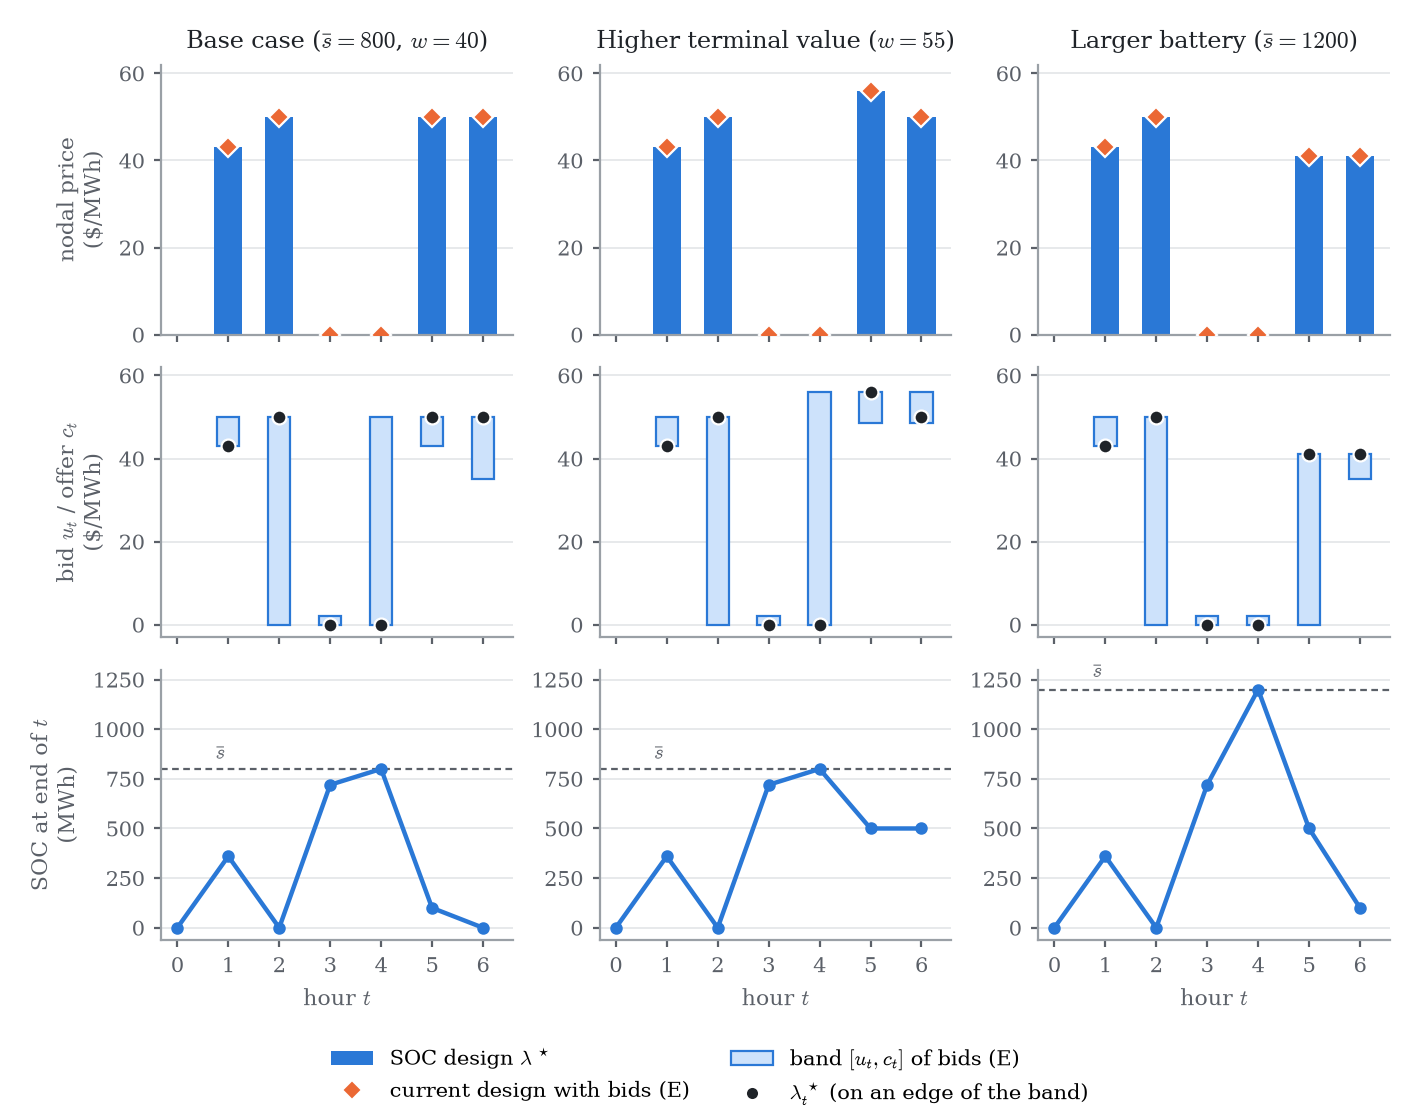

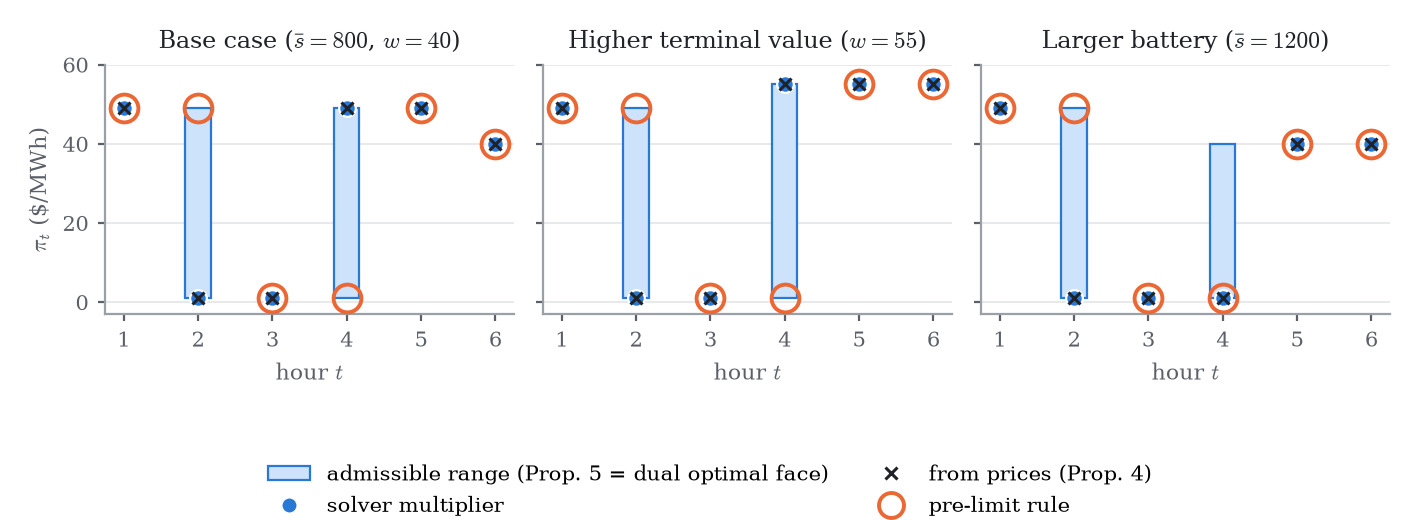

In [10]:
NC.fig_outcome(R); NC.fig_pi(R)
display(Image("figures/fig_check_outcome.png", width=850))
display(Image("figures/fig_check_pi.png", width=850))

## 8. Computational burden

Exact size difference per battery $e$ and interval $t$: the SOC design adds $s_{e,t}$ and rows (A8)–(A10), so

$$\Delta\text{rows}=3ET,\qquad\Delta\text{cols}=ET,\qquad\Delta\text{nnz}=8ET-3E.$$

Below, a reduced grid (one day at hourly and 15-minute resolution) so that the cell runs in seconds. The full grid, including 5-minute resolution, is `python computational_burden.py` (a few minutes).

In [11]:
bench = CB.run(grid=[(24, 1), (24, 50), (96, 50), (96, 200)], reps=1, verbose=False)
df = pd.DataFrame(bench)
df["Δrows = 3ET?"] = (df.rows_soc - df.rows_cd) == 3 * df["T"] * df["E"]
df["Δnnz = 8ET − 3E?"] = (df.nnz_soc - df.nnz_cd) == 8 * df["T"] * df["E"] - 3 * df["E"]
df["simplex ratio SOC/CD"] = df.simplex_soc / df.simplex_cd
df["IPM ratio SOC/CD"] = df.ipm_soc / df.ipm_cd
df[["T", "E", "rows_soc", "rows_cd", "nnz_soc", "nnz_cd", "Δrows = 3ET?", "Δnnz = 8ET − 3E?",
    "simplex ratio SOC/CD", "IPM ratio SOC/CD", "dlam"]]

,T,E,rows_soc,rows_cd,nnz_soc,nnz_cd,Δrows = 3ET?,Δnnz = 8ET − 3E?,simplex ratio SOC/CD,IPM ratio SOC/CD,dlam
0,24,1,1016,944,2581,2392,True,True,1.484,1.346,0.000e+00
1,24,50,4544,944,14194,4744,True,True,4.200,10.799,3.553e-14
2,96,50,18296,3896,57466,19216,True,True,5.007,14.010,1.279e-13
3,96,200,61496,3896,201016,48016,True,True,7.078,54.289,1.080e-12


Timings depend on the machine; the size formulas are exact. `dlam` confirms that in every instance the current design, cleared with the equivalent bids, reproduces the SOC-design prices.